# <a id='toc1_'></a>[MLflow: comparación de experimentos y registro del modelo](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [MLflow: comparación de experimentos y registro del modelo](#toc1_)    
  - [Experimentos registrados](#toc1_1_)    
  - [Selección del mejor modelo](#toc1_2_)    
  - [Evaluación en test](#toc1_3_)    
  - [Registro en el Model Registry](#toc1_4_)    
  - [Comprobación: cargar el modelo como lo hará la app](#toc1_5_)    
  - [Modelo multitarea](#toc1_6_)    
    - [Selección](#toc1_6_1_)    
    - [Evaluación en test](#toc1_6_2_)    
    - [Registro en el Model Registry](#toc1_6_3_)    
    - [Comprobación: cargar el modelo como lo hará la app](#toc1_6_4_)    
  - [Modelo multitarea v2: color y género](#toc1_7_)    
    - [Evaluación en test](#toc1_7_1_)    
    - [Registro y promoción a `champion`](#toc1_7_2_)    
    - [Comprobación: cargar el modelo como lo hará la app](#toc1_7_3_)    
  - [Modelo multitarea v3: género sin color](#toc1_8_)    
    - [Evaluación en test](#toc1_8_1_)    
  - [Resumen](#toc1_9_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook usamos MLflow para comparar los experimentos de `04_modeling` sin volver a entrenar nada: todo (parámetros, métricas y modelos) lo leemos del registro de MLflow. Elegimos los mejores modelos, los evaluamos en test y los registramos en el Model Registry para que la app los use.

**Objetivos:**
1. Recuperar desde MLflow todos los experimentos de una tarea y compararlos.
2. Elegir el mejor por F1-macro en validación.
3. Evaluarlo en test.
4. Registrarlo en el Model Registry con el alias `champion`.
5. Comprobar que el modelo registrado se carga y predice igual que lo hará la app.
6. Repetir la evaluación y el registro con el modelo multitarea.
7. Evaluar el multitarea v2 (con color y género), registrarlo y promocionarlo a `champion`.
8. Evaluar en test el multitarea v3 (experimento de control sin color), sin registrarlo.

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from mlflow import MlflowClient
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import (
    PROCESSED_DATA_DIR, IMAGES_DIR, RANDOM_STATE, REGISTERED_MODEL_NAME, MULTITASK_MODEL_NAME, CHAMPION_ALIAS
)
from fashion_mlops.data.make_dataset import group_rare_classes_in_train, add_multitask_labels
from fashion_mlops.data.dataset import make_loaders
from fashion_mlops.models.train import get_device, predict, compute_metrics
from fashion_mlops.models.multitask import predict_multitask
from fashion_mlops.models.tracking import setup_mlflow
from fashion_mlops.models.predict import (
    load_champion_model, predict_image, load_champion_multitask, predict_image_multitask
)

In [2]:
experiment = setup_mlflow()
client = MlflowClient()
device = get_device()

print(f"Experimento: {experiment.name} (id {experiment.experiment_id})")

Experimento: masterCategory (id 1)


## <a id='toc1_1_'></a>[Experimentos registrados](#toc0_)

Recuperamos todos los runs terminados del experimento, con sus parámetros y sus mejores métricas en validación:

In [3]:
runs = mlflow.search_runs(
    experiment_names=[experiment.name],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["metrics.best_val_f1_macro DESC"],
)

columns = {
    "tags.mlflow.runName": "run",
    "params.freeze_backbone": "congelada",
    "params.class_weights": "pesos",
    "params.lr": "lr",
    "params.epochs": "epocas",
    "metrics.best_epoch": "mejor_epoca",
    "metrics.best_val_f1_macro": "val_f1_macro",
    "metrics.best_val_balanced_accuracy": "val_balanced_acc",
    "metrics.best_val_accuracy": "val_accuracy",
}

runs_table = runs[[col for col in columns if col in runs.columns]].rename(columns=columns)
runs_table.round(4)

,run,congelada,pesos,lr,epocas,mejor_epoca,val_f1_macro,val_balanced_acc,val_accuracy
0,fine_tuning_30ep,False,False,0.0001,30,28.0,0.8467,0.8389,0.9929
1,fine_tuning_weighted_30ep,False,True,0.0001,30,14.0,0.8292,0.8547,0.9861
2,fine_tuning,False,False,0.0001,5,NaN,0.8124,0.8064,0.9928
3,fine_tuning_weighted,False,True,0.0001,5,NaN,0.7985,0.8628,0.9688
4,feature_extraction_30ep,True,False,0.001,30,25.0,0.7678,0.7689,0.9664
5,feature_extraction,True,False,0.001,3,NaN,0.7597,0.7639,0.9603


Las curvas de F1-macro en validación por época también están guardadas en MLflow:

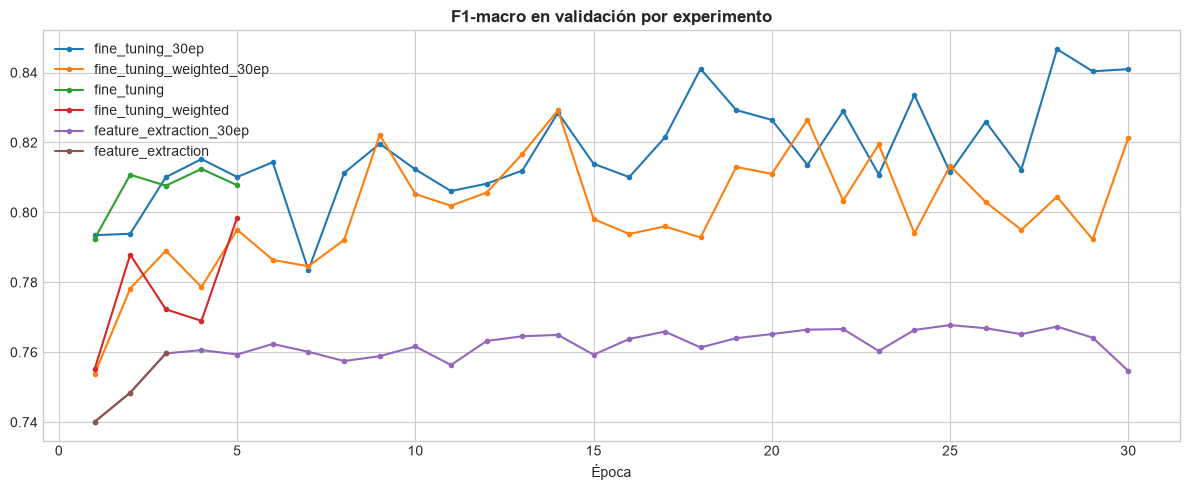

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

for _, run in runs.iterrows():
    history = sorted(client.get_metric_history(run["run_id"], "val_f1_macro"), key=lambda m: m.step)
    values = [m.value for m in history]

    # Numeramos las épocas desde 1 (en los runs _30ep los steps guardados van de 4 a 33, ver 04_modeling)
    ax.plot(range(1, len(values) + 1), values, marker="o", markersize=3, label=run["tags.mlflow.runName"])

ax.set_xlabel("Época")
ax.set_title("F1-macro en validación por experimento", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## <a id='toc1_2_'></a>[Selección del mejor modelo](#toc0_)

Elegimos el run con mejor F1-macro en validación. El test no se ha usado para comparar, solo lo usaremos con el modelo elegido.

In [5]:
best_run = runs.iloc[0]
best_run_id = best_run["run_id"]

# En MLflow 3 cada modelo guardado es un "logged model" asociado a su run
best_model_info = mlflow.search_logged_models(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"source_run_id = '{best_run_id}'",
    output_format="list",
)[0]

print(f"Mejor run: {best_run['tags.mlflow.runName']} ({best_run_id})")
print(f"F1-macro en validación: {best_run['metrics.best_val_f1_macro']:.4f}")

Mejor run: fine_tuning_30ep (2ef9ea637d3049e8b297ffc1d829d691)
F1-macro en validación: 0.8467


## <a id='toc1_3_'></a>[Evaluación en test](#toc0_)

In [6]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")

with open(PROCESSED_DATA_DIR / "label_mappings.json") as f:
    classes = list(json.load(f)["masterCategory"])

test_loader = make_loaders(df, IMAGES_DIR, label_col="masterCategory_idx")["test"]

best_model = mlflow.pytorch.load_model(f"models:/{best_model_info.model_id}").to(device)

y_true, y_pred, y_prob = predict(best_model, test_loader, device)
test_metrics = compute_metrics(y_true, y_pred)

pd.Series(test_metrics).round(4)

accuracy             0.9926
balanced_accuracy    0.8699
f1_macro             0.8995
dtype: float64

In [7]:
print(classification_report(y_true, y_pred, target_names=classes, digits=3, zero_division=0))

               precision    recall  f1-score   support

  Accessories      0.986     0.992     0.989      1610
      Apparel      0.998     0.994     0.996      3056
     Footwear      0.999     0.998     0.998      1317
        Other      1.000     0.368     0.538        19
Personal Care      0.955     0.997     0.976       343

     accuracy                          0.993      6345
    macro avg      0.988     0.870     0.899      6345
 weighted avg      0.993     0.993     0.992      6345



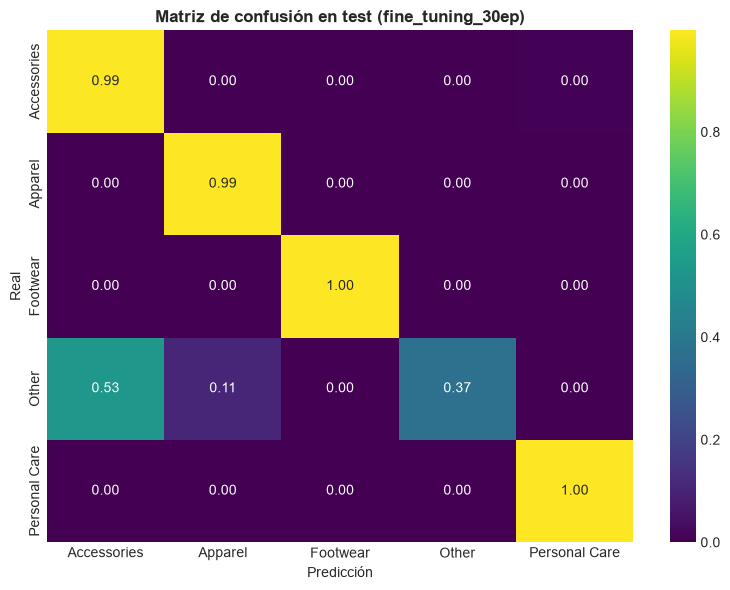

In [8]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión en test ({best_run['tags.mlflow.runName']})", fontweight="bold")
plt.tight_layout()

# Guardamos las métricas de test y la matriz en el run del modelo elegido
with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "confusion_matrix_test.png")

plt.show()

## <a id='toc1_4_'></a>[Registro en el Model Registry](#toc0_)

Registramos el modelo con el nombre `fashion-mastercategory` y le ponemos el alias `champion`. La app cargará siempre `models:/fashion-mastercategory@champion`, así que si en el futuro entrenamos un modelo mejor, basta con mover el alias sin tocar el código de la app.

In [9]:
# Si este run ya está registrado (por ejemplo, al volver a ejecutar el notebook) reutilizamos su versión
existing = client.search_model_versions(f"name = '{REGISTERED_MODEL_NAME}' and run_id = '{best_run_id}'")
model_version = existing[0] if existing else mlflow.register_model(f"models:/{best_model_info.model_id}", REGISTERED_MODEL_NAME)

client.set_registered_model_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS, model_version.version)
client.update_model_version(
    REGISTERED_MODEL_NAME,
    model_version.version,
    description=f"ResNet18 ({best_run['tags.mlflow.runName']}) para clasificar masterCategory a partir de la imagen.",
)

for key, value in {"run_name": best_run["tags.mlflow.runName"],
                   "val_f1_macro": round(best_run["metrics.best_val_f1_macro"], 4),
                   "test_f1_macro": round(test_metrics["f1_macro"], 4)}.items():
    client.set_model_version_tag(REGISTERED_MODEL_NAME, model_version.version, key, value)

print(f"Registrado {REGISTERED_MODEL_NAME} versión {model_version.version} con alias '{CHAMPION_ALIAS}'")

Registrado fashion-mastercategory versión 2 con alias 'champion'


## <a id='toc1_5_'></a>[Comprobación: cargar el modelo como lo hará la app](#toc0_)

Cargamos el modelo desde el registro (por su alias, sin saber qué run es) y predecimos algunas imágenes de test con `predict_image`, la misma función que usará la app:

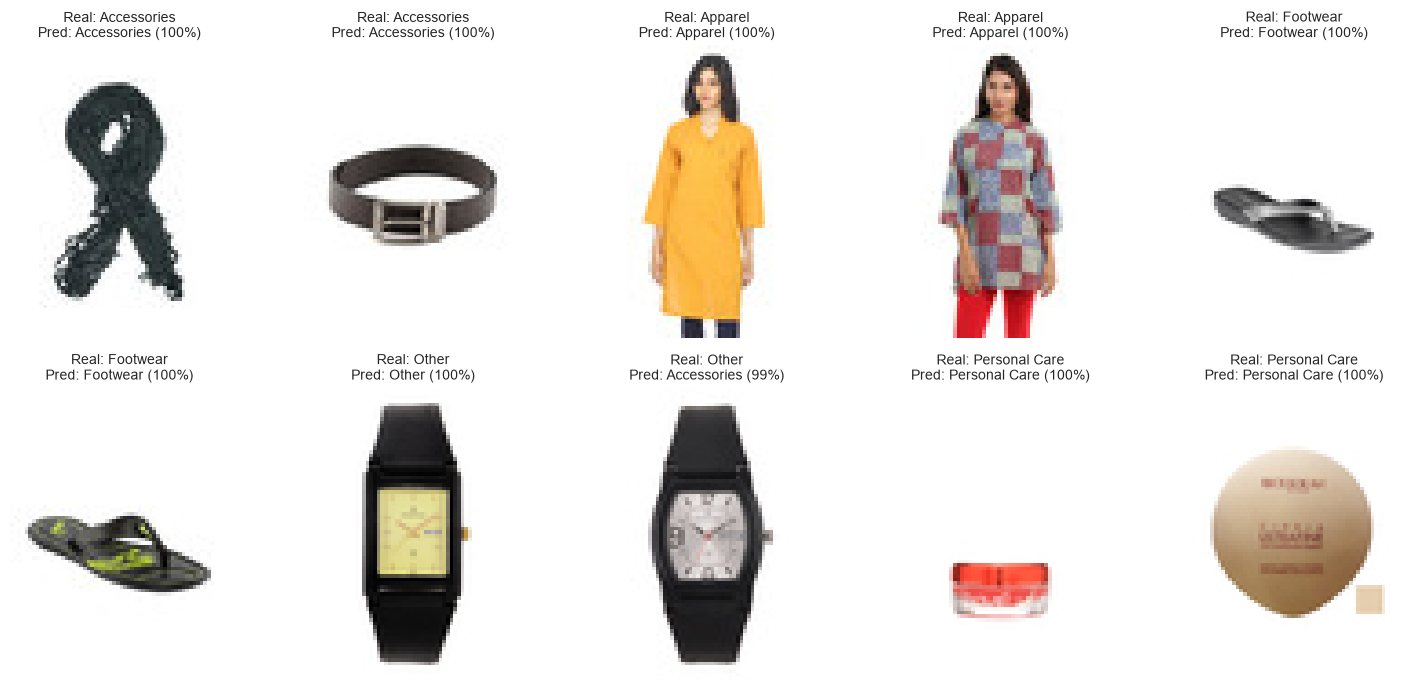

In [10]:
model, model_classes = load_champion_model()

sample = df[df["split"] == "test"].groupby("masterCategory_grouped").sample(2, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    image = Image.open(IMAGES_DIR / f"{row['id']}.jpg")
    probs = predict_image(model, image, model_classes)
    pred, prob = next(iter(probs.items()))

    ax.imshow(image)
    ax.set_title(f"Real: {row['masterCategory_grouped']}\nPred: {pred} ({prob:.0%})", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## <a id='toc1_6_'></a>[Modelo multitarea](#toc0_)

Repetimos el proceso con el modelo multitarea de `04_modeling` (experimento `multitask` de MLflow): lo evaluamos en test en sus tres tareas y lo registramos como un modelo aparte, `fashion-multitask`, con su propio alias `champion`. El modelo de una tarea se queda registrado como estaba, así podemos comparar los dos.

In [11]:
mt_experiment = setup_mlflow(experiment_name="multitask")

print(f"Experimento: {mt_experiment.name} (id {mt_experiment.experiment_id})")

Experimento: multitask (id 2)


### <a id='toc1_6_1_'></a>[Selección](#toc0_)

Elegimos el run multitarea con mejor media del F1-macro de las tres tareas en validación, y recuperamos su modelo y sus mapeos de clases:

In [ ]:
# Seleccionamos el run del multitarea v1 por su nombre: la media del F1-macro solo es comparable
# entre modelos con las mismas tareas (los v2 y v3 tienen otras tareas, ver más abajo)
mt_runs = mlflow.search_runs(
    experiment_names=[mt_experiment.name],
    filter_string="attributes.status = 'FINISHED' and tags.mlflow.runName = 'multitask_fine_tuning_30ep'",
)
mt_best_run = mt_runs.iloc[0]
mt_run_id = mt_best_run["run_id"]

mt_model_info = mlflow.search_logged_models(
    experiment_ids=[mt_experiment.experiment_id],
    filter_string=f"source_run_id = '{mt_run_id}'",
    output_format="list",
)[0]
mt_model = mlflow.pytorch.load_model(f"models:/{mt_model_info.model_id}").to(device)

# Los mapeos de clases se guardaron como artefacto en el run
mt_label_mappings = mlflow.artifacts.load_dict(f"runs:/{mt_run_id}/label_mappings.json")
TASKS = list(mt_label_mappings)

print(f"Run: {mt_best_run['tags.mlflow.runName']} ({mt_run_id}) | mejor época: {mt_best_run['metrics.best_epoch']:.0f}")
pd.Series({task: mt_best_run[f"metrics.best_val_{task}_f1_macro"] for task in TASKS}, name="F1-macro en validación").round(4)

### <a id='toc1_6_2_'></a>[Evaluación en test](#toc0_)

Preparamos las etiquetas de test igual que en el entrenamiento (las clases con menos de 100 imágenes en train van a `Other`) y evaluamos las tres tareas una sola vez:

In [13]:
mt_df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")
min_train_examples = int(mt_best_run["params.min_train_examples"])

mt_df["masterCategory_mt"] = mt_df["masterCategory_grouped"]
for task in ["subCategory", "articleType"]:
    mt_df[f"{task}_mt"] = group_rare_classes_in_train(mt_df, col=task, min_count=min_train_examples)
for task in TASKS:
    mt_df[f"{task}_idx_mt"] = mt_df[f"{task}_mt"].map(mt_label_mappings[task])

mt_test_loader = make_loaders(mt_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS])["test"]

mt_true, mt_pred = predict_multitask(mt_model, mt_test_loader, device, TASKS)
mt_test_metrics = {task: compute_metrics(mt_true[task], mt_pred[task]) for task in TASKS}

# Guardamos las métricas de test en el run del modelo multitarea
with mlflow.start_run(run_id=mt_run_id):
    mlflow.log_metrics({f"test_{task}_{k}": v for task, metrics in mt_test_metrics.items() for k, v in metrics.items()})

pd.DataFrame(mt_test_metrics).T.round(4)

,accuracy,balanced_accuracy,f1_macro
masterCategory,0.9931,0.8697,0.8875
subCategory,0.9677,0.9437,0.9382
articleType,0.8816,0.8477,0.8441


Comparamos `masterCategory` en test con el modelo de una tarea (`champion` de `fashion-mastercategory`), y vemos su matriz de confusión:

masterCategory en test:


,accuracy,balanced_accuracy,f1_macro
una tarea,0.9926,0.8699,0.8995
multitarea,0.9931,0.8697,0.8875


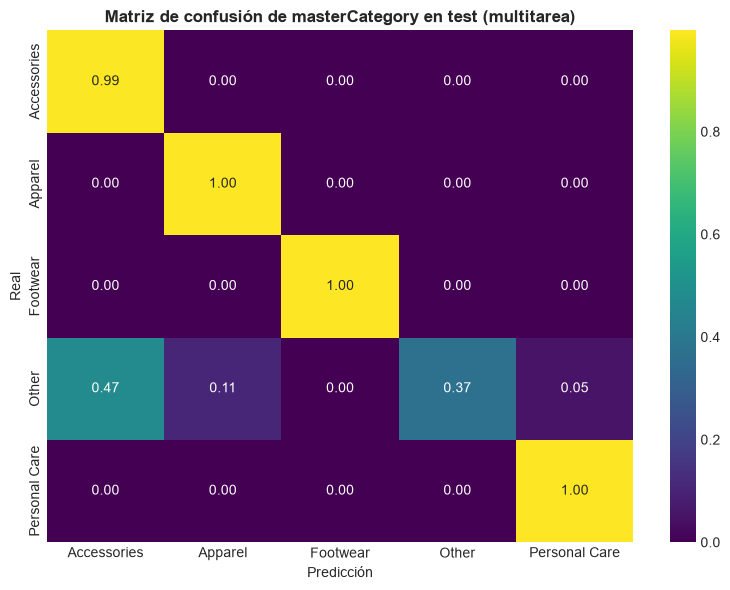

In [14]:
single_task_version = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS)
single_task_metrics = client.get_run(single_task_version.run_id).data.metrics

comparison_master = pd.DataFrame({
    "una tarea": {k: single_task_metrics[f"test_{k}"] for k in ["accuracy", "balanced_accuracy", "f1_macro"]},
    "multitarea": mt_test_metrics["masterCategory"],
}).T
print("masterCategory en test:")
display(comparison_master.round(4))

master_classes = sorted(mt_label_mappings["masterCategory"], key=mt_label_mappings["masterCategory"].get)
cm = confusion_matrix(mt_true["masterCategory"], mt_pred["masterCategory"], normalize="true")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", xticklabels=master_classes, yticklabels=master_classes, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión de masterCategory en test (multitarea)", fontweight="bold")
plt.tight_layout()

with mlflow.start_run(run_id=mt_run_id):
    mlflow.log_figure(fig, "confusion_matrix_masterCategory_test.png")

plt.show()

### <a id='toc1_6_3_'></a>[Registro en el Model Registry](#toc0_)

Lo registramos como `fashion-multitask` con el alias `champion`. Si el run ya estaba registrado, reutilizamos su versión:

In [ ]:
existing = client.search_model_versions(f"name = '{MULTITASK_MODEL_NAME}' and run_id = '{mt_run_id}'")
mt_version = existing[0] if existing else mlflow.register_model(f"models:/{mt_model_info.model_id}", MULTITASK_MODEL_NAME)

# Solo le damos el alias champion si el modelo todavía no tiene ninguno: si ya hay una versión
# promocionada (por ejemplo, el v2), volver a ejecutar esta celda no la desplaza
try:
    client.get_model_version_by_alias(MULTITASK_MODEL_NAME, CHAMPION_ALIAS)
except mlflow.exceptions.MlflowException:
    client.set_registered_model_alias(MULTITASK_MODEL_NAME, CHAMPION_ALIAS, mt_version.version)

client.update_model_version(
    MULTITASK_MODEL_NAME,
    mt_version.version,
    description="ResNet18 multitarea: predice masterCategory, subCategory y articleType a partir de la imagen.",
)

mt_tags = {"run_name": mt_best_run["tags.mlflow.runName"]}
for task in TASKS:
    mt_tags[f"val_{task}_f1_macro"] = round(mt_best_run[f"metrics.best_val_{task}_f1_macro"], 4)
    mt_tags[f"test_{task}_f1_macro"] = round(mt_test_metrics[task]["f1_macro"], 4)

for key, value in mt_tags.items():
    client.set_model_version_tag(MULTITASK_MODEL_NAME, mt_version.version, key, value)

print(f"Registrado {MULTITASK_MODEL_NAME} versión {mt_version.version}")

### <a id='toc1_6_4_'></a>[Comprobación: cargar el modelo como lo hará la app](#toc0_)

Cargamos el modelo multitarea desde el registro por su alias y predecimos las tres tareas de algunas imágenes de test con `predict_image_multitask`:

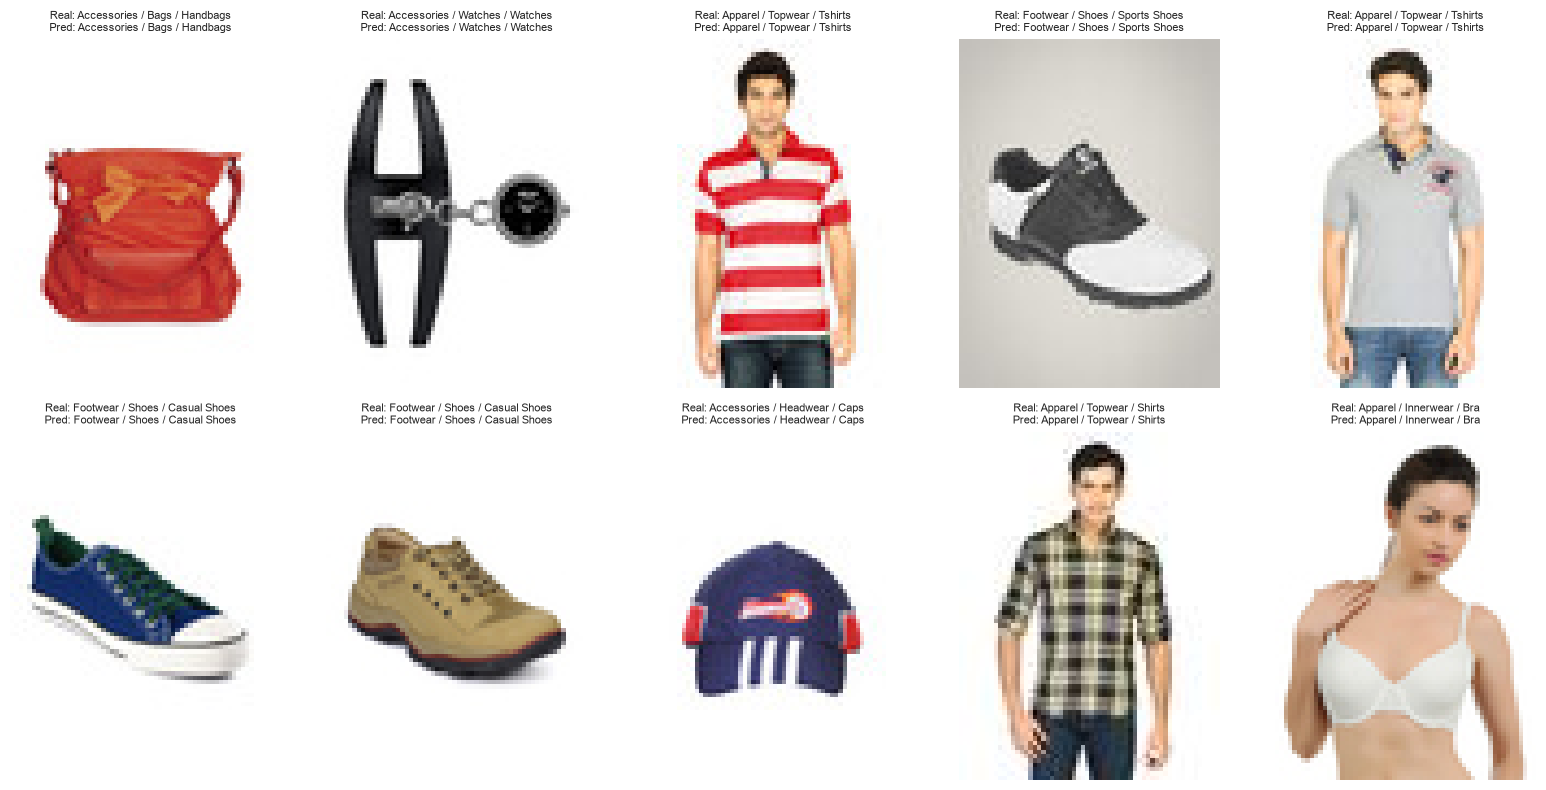

In [16]:
registered_mt_model, mt_classes = load_champion_multitask()

sample = mt_df[mt_df["split"] == "test"].sample(10, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 5, figsize=(16, 8))

for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    image = Image.open(IMAGES_DIR / f"{row['id']}.jpg")
    probs = predict_image_multitask(registered_mt_model, image, mt_classes)
    preds = [next(iter(probs[task])) for task in TASKS]
    real = [row[f"{task}_mt"] for task in TASKS]

    ax.imshow(image)
    ax.set_title(f"Real: {' / '.join(real)}\nPred: {' / '.join(preds)}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

En test, el modelo multitarea consigue un F1-macro de 0,938 en `subCategory` (23 clases) y de 0,844 en `articleType` (50 clases), muy parecido a lo que vimos en validación, así que generaliza bien.

En `masterCategory` queda prácticamente igual que el modelo de una tarea: la misma accuracy (0,993) y balanced accuracy (0,870), y un F1-macro 0,012 más bajo (0,888 frente a 0,900), otra vez una diferencia del tamaño del ruido de `Other`. Con una sola red tenemos tres niveles de detalle sin perder calidad en la categoría principal, y en los ejemplos de arriba acierta los tres niveles en las diez imágenes.

## <a id='toc1_7_'></a>[Modelo multitarea v2: color y género](#toc0_)

El multitarea v2 añade el color (`baseColour`) y el género (`gender`) a las tres tareas del v1. No podemos elegir entre v1 y v2 con la media del F1-macro, porque no tienen las mismas tareas (el v2 incluye el color, que es la tarea más difícil, y su media sale más baja aunque no sea peor modelo). La decisión la tomamos comparando las **tareas comunes** y lo que aporta cada uno a la app.

In [1]:
# Runs del v1 y del v2, por su nombre
v1_run = mlflow.search_runs(experiment_names=["multitask"], filter_string="tags.mlflow.runName = 'multitask_fine_tuning_30ep'").iloc[0]
v2_run = mlflow.search_runs(experiment_names=["multitask"], filter_string="tags.mlflow.runName = 'multitask_v2_fine_tuning_30ep'").iloc[0]
v2_run_id = v2_run["run_id"]

v2_model_info = mlflow.search_logged_models(
    experiment_ids=[mt_experiment.experiment_id], filter_string=f"source_run_id = '{v2_run_id}'", output_format="list"
)[0]
v2_model = mlflow.pytorch.load_model(f"models:/{v2_model_info.model_id}").to(device)
v2_label_mappings = mlflow.artifacts.load_dict(f"runs:/{v2_run_id}/label_mappings.json")
TASKS_V2 = list(v2_label_mappings)

print(f"Run: {v2_run['tags.mlflow.runName']} ({v2_run_id}) | mejor época: {v2_run['metrics.best_epoch']:.0f}")
pd.Series({task: v2_run[f"metrics.best_val_{task}_f1_macro"] for task in TASKS_V2}, name="F1-macro en validación").round(4)

Run: multitask_v2_fine_tuning_30ep (b761201e73f84d25b372b064d32264ab) | mejor época: 27


masterCategory    0.8124
subCategory       0.9360
articleType       0.8450
baseColour        0.5097
gender            0.8128
Name: F1-macro en validación, dtype: float64

### <a id='toc1_7_1_'></a>[Evaluación en test](#toc0_)

Evaluamos las cinco tareas en test y comparamos las tres comunes con el v1:

In [2]:
v2_df = add_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"),
    label_mappings=v2_label_mappings,
    min_count=int(v2_run["params.min_train_examples"]),
)
v2_test_loader = make_loaders(v2_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS_V2])["test"]

v2_true, v2_pred = predict_multitask(v2_model, v2_test_loader, device, TASKS_V2)
v2_test_metrics = {task: compute_metrics(v2_true[task], v2_pred[task]) for task in TASKS_V2}

with mlflow.start_run(run_id=v2_run_id):
    mlflow.log_metrics({f"test_{task}_{k}": v for task, metrics in v2_test_metrics.items() for k, v in metrics.items()})

display(pd.DataFrame(v2_test_metrics).T.round(4))

# Comparación con el v1 en las tareas comunes (F1-macro en test)
pd.DataFrame({
    task: {"v1 (3 tareas)": v1_run.get(f"metrics.test_{task}_f1_macro"), "v2 (5 tareas)": v2_test_metrics[task]["f1_macro"]}
    for task in TASKS_V2
}).T.round(4)

,accuracy,balanced_accuracy,f1_macro
masterCategory,0.9928,0.8455,0.8694
subCategory,0.9682,0.9325,0.9377
articleType,0.8832,0.8243,0.8348
baseColour,0.6662,0.4925,0.5016
gender,0.9203,0.7508,0.7795


,v1 (3 tareas),v2 (5 tareas)
masterCategory,0.8875,0.8694
subCategory,0.9382,0.9377
articleType,0.8441,0.8348
baseColour,NaN,0.5016
gender,NaN,0.7795


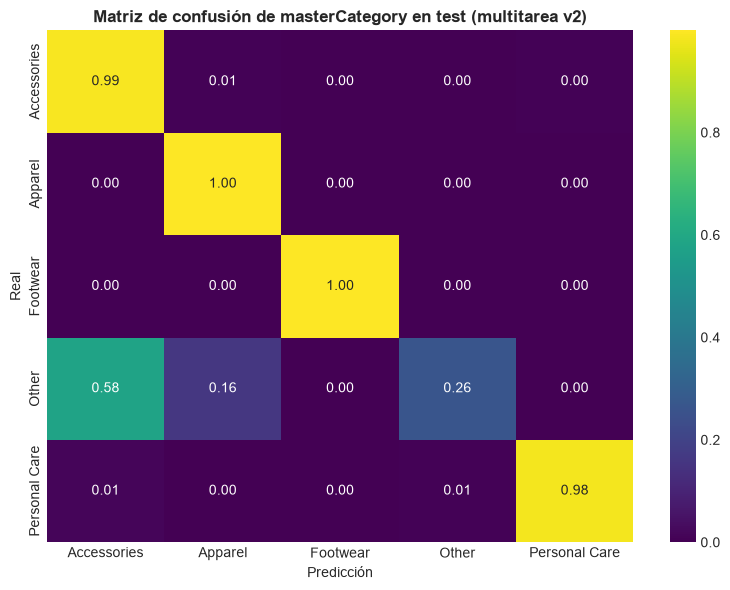

In [3]:
# Matriz de confusión de la categoría principal, guardada en el run (la muestra la app)
v2_master_classes = sorted(v2_label_mappings["masterCategory"], key=v2_label_mappings["masterCategory"].get)
cm = confusion_matrix(v2_true["masterCategory"], v2_pred["masterCategory"], normalize="true")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", xticklabels=v2_master_classes, yticklabels=v2_master_classes, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión de masterCategory en test (multitarea v2)", fontweight="bold")
plt.tight_layout()

with mlflow.start_run(run_id=v2_run_id):
    mlflow.log_figure(fig, "confusion_matrix_masterCategory_test.png")

plt.show()

### <a id='toc1_7_2_'></a>[Registro y promoción a `champion`](#toc0_)

Registramos el v2 como nueva versión de `fashion-multitask` y le pasamos el alias `champion`, así que la app empezará a usarlo. **Por qué el v2:** pierde muy poco en las tareas comunes y a cambio añade el color y el género, que la app usa para mostrar más información, buscar productos del mismo color y, en el futuro, combinar prendas. Dejamos la justificación guardada en la versión del registro, para que la decisión quede documentada en MLflow.

In [4]:
existing = client.search_model_versions(f"name = '{MULTITASK_MODEL_NAME}' and run_id = '{v2_run_id}'")
v2_version = existing[0] if existing else mlflow.register_model(f"models:/{v2_model_info.model_id}", MULTITASK_MODEL_NAME)

previous_champion = client.get_model_version_by_alias(MULTITASK_MODEL_NAME, CHAMPION_ALIAS).version
client.set_registered_model_alias(MULTITASK_MODEL_NAME, CHAMPION_ALIAS, v2_version.version)

client.update_model_version(
    MULTITASK_MODEL_NAME,
    v2_version.version,
    description="ResNet18 multitarea v2: predice masterCategory, subCategory, articleType, baseColour y gender a partir de la imagen.",
)

v2_tags = {
    "run_name": v2_run["tags.mlflow.runName"],
    "promotion_reason": "Añade color y género (para la app y la futura recomendación de looks) con una pérdida pequeña en las tareas comunes respecto al v1.",
}
for task in TASKS_V2:
    v2_tags[f"val_{task}_f1_macro"] = round(v2_run[f"metrics.best_val_{task}_f1_macro"], 4)
    v2_tags[f"test_{task}_f1_macro"] = round(v2_test_metrics[task]["f1_macro"], 4)

for key, value in v2_tags.items():
    client.set_model_version_tag(MULTITASK_MODEL_NAME, v2_version.version, key, value)

print(f"Registrado {MULTITASK_MODEL_NAME} versión {v2_version.version}; el alias '{CHAMPION_ALIAS}' pasa de la versión {previous_champion} a la {v2_version.version}")

Registrado fashion-multitask versión 2; el alias 'champion' pasa de la versión 1 a la 2


Registered model 'fashion-multitask' already exists. Creating a new version of this model...
Created version '2' of model 'fashion-multitask'.


### <a id='toc1_7_3_'></a>[Comprobación: cargar el modelo como lo hará la app](#toc0_)

Cargamos el `champion` desde el registro (ahora el v2) y predecimos las cinco tareas de algunas imágenes de test:

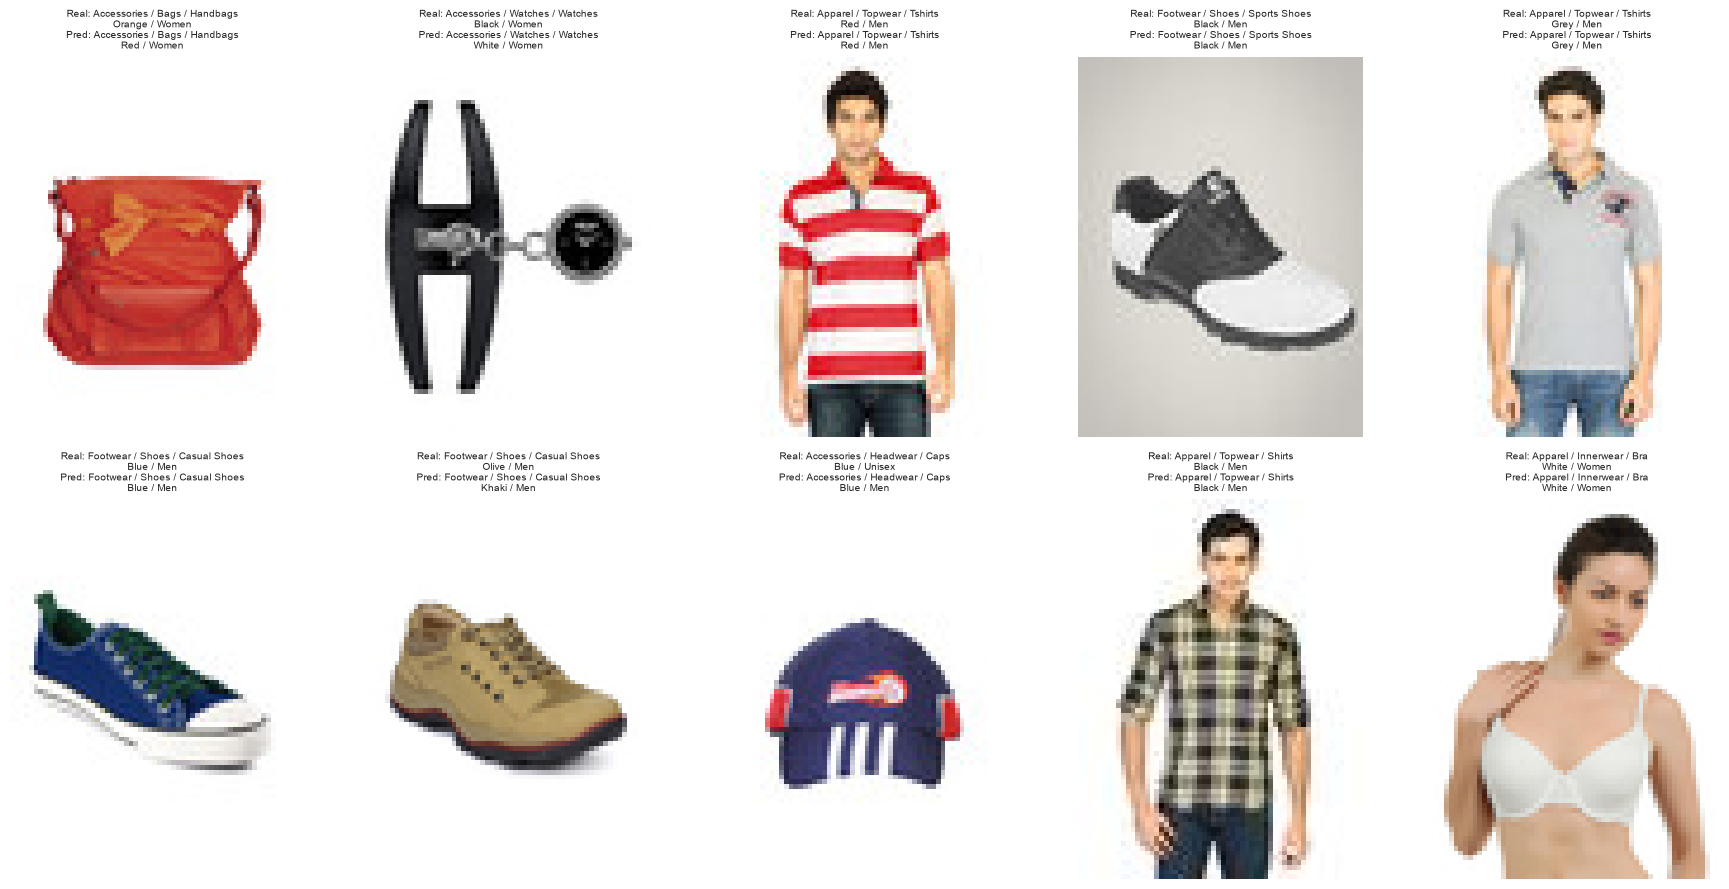

In [5]:
champion_model, champion_classes = load_champion_multitask()

sample = v2_df[v2_df["split"] == "test"].sample(10, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 5, figsize=(18, 9))

for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    image = Image.open(IMAGES_DIR / f"{row['id']}.jpg")
    probs = predict_image_multitask(champion_model, image, champion_classes)
    preds = [next(iter(probs[task])) for task in TASKS_V2]
    real = [row[f"{task}_mt"] for task in TASKS_V2]

    ax.imshow(image)
    ax.set_title(f"Real: {' / '.join(real[:3])}\n{' / '.join(real[3:])}\nPred: {' / '.join(preds[:3])}\n{' / '.join(preds[3:])}", fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()

En test, el v2 reconoce el color con una accuracy de 0,666 (F1-macro 0,502, 28 colores) y el género con una accuracy de 0,920 (F1-macro 0,780). En las tareas comunes pierde muy poco respecto al v1: la subcategoría queda igual (0,938), el tipo baja 0,009 (0,835 frente a 0,844) y la categoría 0,018 (0,869 frente a 0,888, otra vez dentro del ruido de `Other`).

Con esto el v2 pasa a ser el `champion` de `fashion-multitask` y la app lo usa sin cambiar el código del modelo. El color hay que tomarlo como orientativo: acierta los colores básicos, pero confunde tonos parecidos como azul y azul marino o negro y gris.

## <a id='toc1_8_'></a>[Modelo multitarea v3: género sin color](#toc0_)

El v3 es el experimento de control de `04_modeling`: las tareas del v2 sin el color, para ver si la pérdida del v2 en el tipo de artículo la provoca el color. No lo registramos en el Model Registry porque no va a la app, pero lo evaluamos en test para completar la comparación y guardamos las métricas en su run.

In [6]:
# Run del v3, por su nombre (los del v1 y el v2 ya los tenemos de las secciones anteriores)
v3_run = mlflow.search_runs(experiment_names=["multitask"], filter_string="tags.mlflow.runName = 'multitask_v3_fine_tuning_30ep'").iloc[0]
v3_run_id = v3_run["run_id"]

v3_model_info = mlflow.search_logged_models(
    experiment_ids=[mt_experiment.experiment_id], filter_string=f"source_run_id = '{v3_run_id}'", output_format="list"
)[0]
v3_model = mlflow.pytorch.load_model(f"models:/{v3_model_info.model_id}").to(device)
v3_label_mappings = mlflow.artifacts.load_dict(f"runs:/{v3_run_id}/label_mappings.json")
TASKS_V3 = list(v3_label_mappings)

print(f"Run: {v3_run['tags.mlflow.runName']} ({v3_run_id}) | mejor época: {v3_run['metrics.best_epoch']:.0f}")

Run: multitask_v3_fine_tuning_30ep (e29126ef519a4abcae942b8e31fb43cf) | mejor época: 17


### <a id='toc1_8_1_'></a>[Evaluación en test](#toc0_)

Evaluamos las cuatro tareas en test y comparamos con el v1 y el v2:

In [7]:
v3_df = add_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"),
    label_mappings=v3_label_mappings,
    min_count=int(v3_run["params.min_train_examples"]),
)
v3_test_loader = make_loaders(v3_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS_V3])["test"]

v3_true, v3_pred = predict_multitask(v3_model, v3_test_loader, device, TASKS_V3)
v3_test_metrics = {task: compute_metrics(v3_true[task], v3_pred[task]) for task in TASKS_V3}

with mlflow.start_run(run_id=v3_run_id):
    mlflow.log_metrics({f"test_{task}_{k}": v for task, metrics in v3_test_metrics.items() for k, v in metrics.items()})

display(pd.DataFrame(v3_test_metrics).T.round(4))

# Comparación de los tres modelos multitarea (F1-macro en test)
pd.DataFrame({
    "v1 (3 tareas)": {task: v1_run.get(f"metrics.test_{task}_f1_macro") for task in TASKS_V3},
    "v2 (5 tareas)": {task: v2_test_metrics[task]["f1_macro"] for task in TASKS_V3},
    "v3 (sin color)": {task: v3_test_metrics[task]["f1_macro"] for task in TASKS_V3},
}).round(4)

,accuracy,balanced_accuracy,f1_macro
masterCategory,0.9948,0.8394,0.8579
subCategory,0.9719,0.9531,0.9482
articleType,0.8887,0.8535,0.8511
gender,0.9234,0.7771,0.7808


,v1 (3 tareas),v2 (5 tareas),v3 (sin color)
masterCategory,0.8875,0.8694,0.8579
subCategory,0.9382,0.9377,0.9482
articleType,0.8441,0.8348,0.8511
gender,NaN,0.7795,0.7808


En test se confirma lo que vimos en validación: sin el color, el tipo de artículo sube a 0,851 (frente a 0,835 del v2 y 0,844 del v1) y la subcategoría a 0,948. El género queda igual que en el v2 (0,781 frente a 0,780).

Es decir, la pérdida del v2 la provoca el color y no el número de tareas. Aun así, la app sigue con el v2: la diferencia es pequeña y el color le aporta información y la búsqueda de productos del mismo color.

## <a id='toc1_9_'></a>[Resumen](#toc0_)

- Hemos comparado los seis experimentos de una tarea de `04_modeling` leyendo todo de MLflow (parámetros, métricas por época y modelos), sin volver a entrenar.
- El mejor en validación es el fine-tuning con 30 épocas (`fine_tuning_30ep`, F1-macro 0,847).
- **En test:** accuracy 0,993, balanced accuracy 0,870 y F1-macro 0,899. Mejora claramente a la versión anterior (fine-tuning de 5 épocas, F1-macro 0,846 en test).
- La mejora viene casi toda de `Other`: ahora reconoce 7 de sus 19 imágenes sin ningún falso positivo (F1 0,538 frente a 0,261). Las cuatro categorías visuales siguen por encima de 0,97 de F1.
- Lo hemos registrado como **versión 2** de `fashion-mastercategory` y el alias `champion` ha pasado de la versión 1 a la 2.
- **Modelo multitarea v1**, en test: F1-macro 0,888 en `masterCategory`, 0,938 en `subCategory` y 0,844 en `articleType`. En la categoría principal queda prácticamente igual que el modelo de una tarea y además da el tipo concreto de producto. Registrado como `fashion-multitask` versión 1.
- **Modelo multitarea v2**, en test: añade el color (accuracy 0,666, F1-macro 0,502) y el género (accuracy 0,920, F1-macro 0,780) perdiendo muy poco en las tareas comunes (tipo 0,835). Lo hemos registrado como `fashion-multitask` versión 2 y lo hemos **promocionado a `champion`**, dejando la justificación guardada en el registro: es el modelo que usa la app.
- **Modelo multitarea v3** (control, sin color), en test: tipo 0,851, subcategoría 0,948 y género 0,781. Mejora al v2 en el tipo, lo que confirma que la pérdida del v2 la provoca el color. No lo registramos porque no va a la app.
- Al cargar los modelos desde el registro por su alias, predicen correctamente las imágenes de prueba, igual que lo hará la app.

En `06_deployment` calcularemos los embeddings del catálogo y lanzaremos la app de Streamlit.